In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Task 1. Ilkin tehlil

In [2]:
data = pd.read_csv("./data/Used_Cars_Homework.csv")
data.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [3]:
data.shape

(300, 9)

In [4]:
data.dtypes

age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                   str
fuel_type               str
transmission            str
accident_history        str
price_azn             int64
dtype: object

In [5]:
data.isna().sum()

age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

In [6]:
data.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [7]:
data["price_azn"].min(), data["price_azn"].max(), data["price_azn"].mean()

(np.int64(3805), np.int64(51396), np.float64(27806.573333333334))

# Task 2. Vizuallashdirma

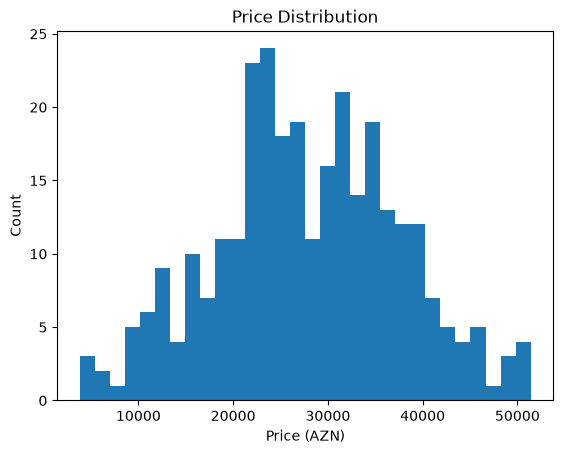

In [8]:
plt.hist(data["price_azn"], bins=30)
plt.title("Price Distribution")
plt.xlabel("Price (AZN)")
plt.ylabel("Count")
plt.show()

**Netice:** Orta qiymete yaxin mashinlar choxdu, max ve min qiymete yaxin mashinlarin sayi azdi

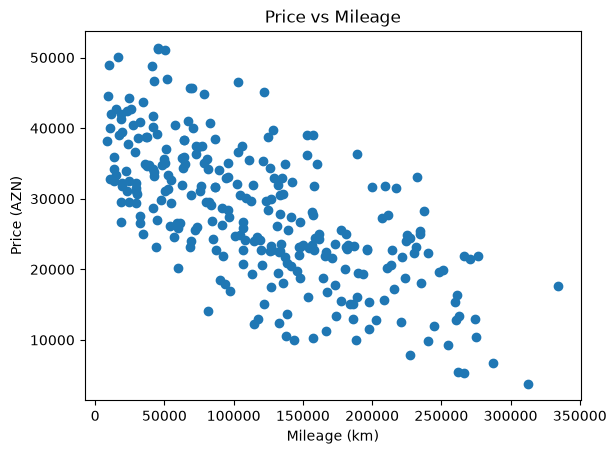

In [9]:
plt.scatter(data["mileage_km"], data["price_azn"])
plt.title("Price vs Mileage")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (AZN)")
plt.show()

**Netice:** Yurush artdiqca qiymet azalir

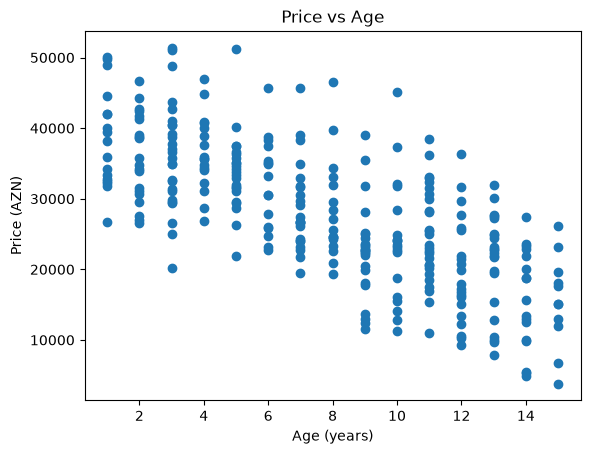

In [10]:
plt.scatter(data["age_years"], data["price_azn"])
plt.title("Price vs Age")
plt.xlabel("Age (years)")
plt.ylabel("Price (AZN)")
plt.show()

**Netice:** Mashinin yashi artdiqca qiymeti azalir

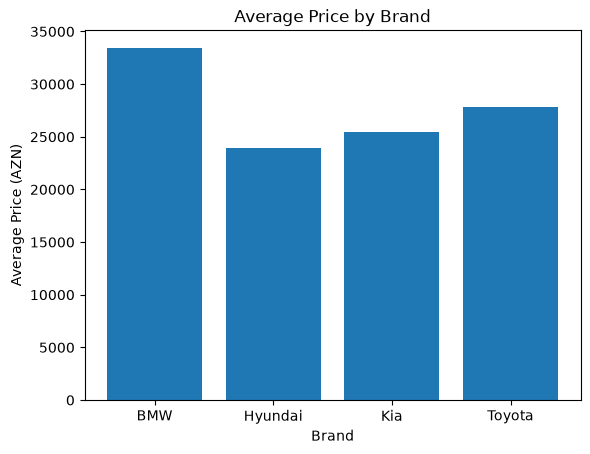

In [11]:
brand_mean = data.groupby("brand")["price_azn"].mean()
plt.bar(brand_mean.index, brand_mean.values)
plt.title("Average Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (AZN)")
plt.show()

**Netice:** En bahali marka BMW, en ucuz Hyundai

# Task 3. Datanin hazirlanmasi

In [12]:
X = data.drop(columns=["price_azn"])
y = data["price_azn"]
X["mileage_per_year"] = X["mileage_km"] / X["age_years"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
num_features = ["age_years", "mileage_km", "engine_l", "power_hp", "mileage_per_year"]
cat_features = ["brand", "fuel_type", "transmission", "accident_history"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [14]:
train_copy = X_train.copy()
train_copy["brand_factorize"], brand_uniques = pd.factorize(train_copy["brand"])
print(list(brand_uniques))
train_copy[["brand", "brand_factorize"]].head(10)

['BMW', 'Toyota', 'Kia', 'Hyundai']


,brand,brand_factorize
232,BMW,0
59,Toyota,1
6,Toyota,1
185,BMW,0
173,Toyota,1
30,BMW,0
22,Toyota,1
256,Toyota,1
56,Kia,2
186,BMW,0


In [15]:
brand_ohe = pd.get_dummies(train_copy["brand"], prefix="brand", dtype=int)
pd.concat([train_copy["brand"], brand_ohe], axis=1).head(10)

,brand,brand_BMW,brand_Hyundai,brand_Kia,brand_Toyota
232,BMW,1,0,0,0
59,Toyota,0,0,0,1
6,Toyota,0,0,0,1
185,BMW,1,0,0,0
173,Toyota,0,0,0,1
30,BMW,1,0,0,0
22,Toyota,0,0,0,1
256,Toyota,0,0,0,1
56,Kia,0,0,1,0
186,BMW,1,0,0,0


In [16]:
mileage = X_train[["mileage_km"]].copy()
mileage = mileage.fillna(mileage.median())

mileage_demo = mileage.copy()
mileage_demo["minmax"] = MinMaxScaler().fit_transform(mileage)
mileage_demo["standard"] = StandardScaler().fit_transform(mileage)
mileage_demo.head(10)

,mileage_km,minmax,standard
232,52670.0,0.135150,-0.928737
59,81580.0,0.223927,-0.522960
6,124854.0,0.356814,0.084429
185,115668.0,0.328605,-0.044505
173,15054.0,0.019638,-1.456711
30,276575.0,0.822722,2.213966
22,193325.0,0.567076,1.045479
256,120461.0,0.343324,0.022769
56,189012.0,0.553831,0.984943
186,78885.0,0.215651,-0.560787


**Ferqler:**
- `factorize` her markaya ferqli eded verir
- `One-Hot Encoding` her marka ucun ayri sutun yaradir ve ora 0 ve ya 1 yazir
- `MinMaxScaler` butun deyerleri 0 ve 1 arasina salir
- `StandardScaler` deyerlerin ortasini 0 edir, yayilmani 1 edir

# Task 4. Modelin oyredilmesi ve qiymetlendirilmesi

In [17]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"""
MAE = {mae:.2f}
MSE = {mse:.2f}
RMSE = {rmse:.2f}
R2 = {r2:.4f}
""")


MAE = 1414.62
MSE = 2886404.32
RMSE = 1698.94
R2 = 0.9718



**Netice:**
- **MAE**: model orta hesabla qiymeti 1 414 manatla sehv proqnozlashdirir
- **MSE**: manat^2 ile hesablandigina gore birshey demek chetindi
- **RMSE**: MAE den biraz boyukdur, yeni bezi xetalar nisbeten boyukdur 
- **R2**: model qiymetleri 97% deqiqlikle duzgun tapib

In [18]:
results = pd.DataFrame({
    "Real price": y_test.values,
    "Predicted price": y_pred.round(2),
})
results["Absolute error"] = (results["Real price"] - results["Predicted price"]).abs().round(2)
results.head(10)

,Real price,Predicted price,Absolute error
0,34837,32094.81,2742.19
1,34946,33157.90,1788.10
2,32214,31152.66,1061.34
3,36190,35780.66,409.34
4,25000,23648.31,1351.69
5,26522,27360.10,838.10
6,22711,24210.68,1499.68
7,33061,32078.44,982.56
8,18479,19693.81,1214.81
9,25003,23457.43,1545.57


# Task 5. Oyrenmenin yoxlanilmasi

In [19]:
train_sizes, train_scores, cv_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)
pd.DataFrame({"Train size": train_sizes, "Train R2": train_mean, "CV R2": cv_mean})

,Train size,Train R2,CV R2
0,19,0.980896,0.772580
1,62,0.947216,0.944793
2,105,0.953372,0.940661
3,148,0.956109,0.946009
4,192,0.957351,0.946740


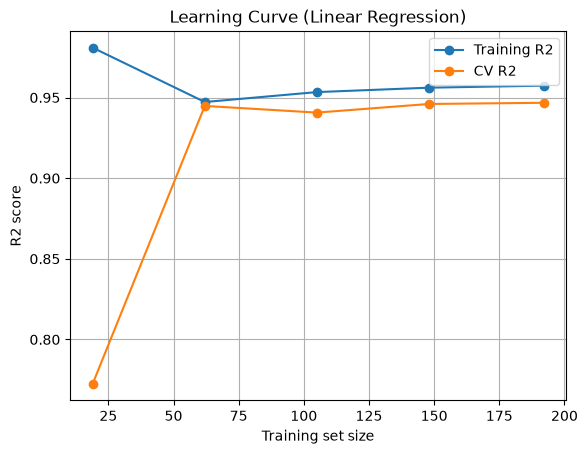

In [20]:
plt.plot(train_sizes, train_mean, "o-", label="Training R2")
plt.plot(train_sizes, cv_mean, "o-", label="CV R2")
plt.title("Learning Curve (Linear Regression)")
plt.xlabel("Training set size")
plt.ylabel("R2 score")
plt.legend(loc="best")
plt.grid(True)
plt.show()

**Netice:** her ikisi melumat sayi artdiqca bir birine yaxinlashir, yeni demek olarki overfitting yoxdu

# Task 6. Yeni masinlar ucun proqnoz

In [21]:
new_cars = pd.DataFrame({
    "age_years": [5, 10, 3],
    "mileage_km": [75000, 180000, 40000],
    "engine_l": [1.6, 2.0, 2.5],
    "power_hp": [110, 140, 170],
    "brand": ["Toyota", "Hyundai", "BMW"],
    "fuel_type": ["petrol", "diesel", "petrol"],
    "transmission": ["automatic", "manual", "automatic"],
    "accident_history": ["no", "yes", "no"],
})
new_cars["mileage_per_year"] = new_cars["mileage_km"] / new_cars["age_years"]
new_cars["predicted_price_azn"] = model.predict(new_cars).round(2)
new_cars[["brand", "age_years", "mileage_km", "predicted_price_azn"]]

,brand,age_years,mileage_km,predicted_price_azn
0,Toyota,5,75000,31170.63
1,Hyundai,10,180000,15912.01
2,BMW,3,40000,48791.50
